# Bangladesh Rent Prediction: Modeling
**Goal:** predict monthly rent (BDT) from area, beds, baths, type, city and locality.
**Target:** log(rent), because rent is right-skewed.
**Metrics:** R², MAE (BDT) and RMSE on log scale.

## 1. Data and train/test split
Features go through a Scikit-learn `Pipeline` so scaling and encoding are fit on training data only (no leakage). 80% of rows are used for training and 20% are held out for testing.

In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

d = pd.read_csv("../data/clean.csv")
X = d[["area_sqft", "beds_n", "bath_n", "type", "city", "locality"]]
y = np.log1p(d["price_num"])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_tr.shape, X_te.shape)

(5958, 6) (1490, 6)


## 2. Preprocessing pipeline
- Numeric features (`area_sqft`, `beds_n`, `bath_n`) are standardized.
- Categorical features (`type`, `city`, `locality`) are one-hot encoded; unseen categories are ignored at prediction time.

In [4]:
num = ["area_sqft", "beds_n", "bath_n"]
cat = ["type", "city", "locality"]
pre = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
])

## 3. Baseline and first model
A median-predicting baseline sets the minimum bar. Ridge regression (linear model with regularization) is the first real model.

In [3]:
def evaluate(model, name):
    pipe = Pipeline([("pre", pre), ("model", model)]).fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    mae = mean_absolute_error(np.expm1(y_te), np.expm1(pred))
    print(f"{name}: R2={r2_score(y_te, pred):.3f}  MAE={mae:,.0f} BDT  RMSE(log)={root_mean_squared_error(y_te, pred):.3f}")

evaluate(DummyRegressor(strategy="median"), "Baseline (median)")
evaluate(Ridge(alpha=1.0), "Ridge")

Baseline (median): R2=-0.055  MAE=15,655 BDT  RMSE(log)=0.675
Ridge: R2=0.874  MAE=6,068 BDT  RMSE(log)=0.233


**Results:**
- Baseline: R² = -0.055, MAE = 15,655 BDT.
- Ridge: R² = 0.874, MAE = 6,068 BDT, a 61% reduction in MAE over the baseline.

## 4. Tree-based models and cross-validation
Random Forest and Histogram Gradient Boosting can model non-linear effects and feature interactions (e.g. area matters more in Gulshan than in Mirpur). I compare all models with 5-fold cross-validation on the training set, so the choice doesn't depend on one lucky split.

In [5]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score

pre_dense = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
])

models = {
    "Ridge": Pipeline([("pre", pre), ("m", Ridge(alpha=1.0))]),
    "RandomForest": Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))]),
    "HistGB": Pipeline([("pre", pre_dense), ("m", HistGradientBoostingRegressor(random_state=42))]),
}

for name, pipe in models.items():
    cv = -cross_val_score(pipe, X_tr, y_tr, cv=5, scoring="neg_root_mean_squared_error")
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    mae = mean_absolute_error(np.expm1(y_te), np.expm1(pred))
    print(f"{name}: CV RMSE(log)={cv.mean():.3f}±{cv.std():.3f} | test R2={r2_score(y_te, pred):.3f} MAE={mae:,.0f} BDT")

Ridge: CV RMSE(log)=0.235±0.010 | test R2=0.874 MAE=6,068 BDT
RandomForest: CV RMSE(log)=0.217±0.006 | test R2=0.887 MAE=5,203 BDT
HistGB: CV RMSE(log)=0.212±0.006 | test R2=0.896 MAE=5,344 BDT


Ridge: CV RMSE 0.235, test R² 0.874, MAE 6,068 BDT
Random Forest: CV RMSE 0.217, test R² 0.887, MAE 5,203 BDT
HistGB: CV RMSE 0.212, test R² 0.896, MAE 5,344 BDT

HistGB has the lowest CV error, so I tune it. Random Forest has a slightly lower test MAE, but the difference is small.

## 5. Tuning HistGB
Random search over learning rate, tree depth, number of iterations and regularization, scored with 5-fold CV on the training set. The test set is not used here.

In [6]:
from sklearn.model_selection import RandomizedSearchCV

pipe = Pipeline([("pre", pre_dense), ("m", HistGradientBoostingRegressor(random_state=42))])

params = {
    "m__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "m__max_iter": [200, 400, 600],
    "m__max_depth": [None, 4, 6, 8],
    "m__min_samples_leaf": [10, 20, 40],
    "m__l2_regularization": [0, 0.1, 1.0],
}

search = RandomizedSearchCV(pipe, params, n_iter=20, cv=5,
                            scoring="neg_root_mean_squared_error",
                            random_state=42, n_jobs=-1)
search.fit(X_tr, y_tr)

print(search.best_params_)
print("best CV RMSE:", -search.best_score_)

{'m__min_samples_leaf': 10, 'm__max_iter': 200, 'm__max_depth': 6, 'm__learning_rate': 0.2, 'm__l2_regularization': 1.0}
best CV RMSE: 0.2068137007541837


## 6. Final test score
The tuned model is evaluated once on the held-out test set.

In [7]:
best = search.best_estimator_
pred = best.predict(X_te)
print("R2:", round(r2_score(y_te, pred), 3))
print("MAE:", round(mean_absolute_error(np.expm1(y_te), np.expm1(pred))), "BDT")
print("RMSE(log):", round(root_mean_squared_error(y_te, pred), 3))

R2: 0.899
MAE: 5298 BDT
RMSE(log): 0.209


Tuned HistGB on the test set: R² 0.899, MAE 5,298 BDT, RMSE(log) 0.209.
Tuning gave a small gain over the untuned model (R² 0.896, MAE 5,344).

## 7. Feature importance
Permutation importance: shuffle one column at a time on the test set and see how much the error goes up.

area_sqft    0.479999
locality     0.137085
city         0.033817
bath_n       0.024949
beds_n       0.016582
type         0.000806
dtype: float64


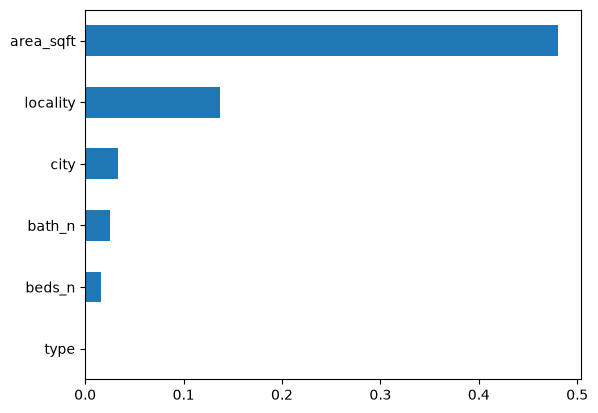

In [8]:
from sklearn.inspection import permutation_importance

r = permutation_importance(best, X_te, y_te, n_repeats=10, random_state=42,
                           scoring="neg_root_mean_squared_error")
imp = pd.Series(r.importances_mean, index=X_te.columns).sort_values(ascending=False)
print(imp)
imp.plot.barh().invert_yaxis()

Area is by far the most important feature (RMSE rises by 0.48 when shuffled), then locality (0.14). City (0.03), baths (0.02) and beds (0.02) matter much less. Type is close to zero, which makes sense since almost every listing is an apartment.
City adds little on top of locality because locality already says which city a listing is in.

## 8. Error analysis
Looking at where the model is off: by city, by rent level, by locality, and the worst single predictions.

In [9]:
res = X_te.copy()
res["actual"] = np.expm1(y_te)
res["pred"] = np.expm1(pred)
res["abs_err"] = (res["actual"] - res["pred"]).abs()
res["pct_err"] = res["abs_err"] / res["actual"] * 100

print("median % error:", round(res["pct_err"].median(), 1))
print(res.groupby("city")[["abs_err", "pct_err"]].median().round(1))

res["band"] = pd.qcut(res["actual"], 4, labels=["low", "mid-low", "mid-high", "high"])
print(res.groupby("band", observed=True)[["abs_err", "pct_err"]].median().round(1))

loc = res.groupby("locality").agg(n=("abs_err", "size"), mae=("abs_err", "mean"))
print(loc[loc["n"] >= 10].sort_values("mae", ascending=False).head(5).round(0))

cols = ["locality", "area_sqft", "beds_n", "actual", "pred"]
print(res.sort_values("abs_err", ascending=False).head(5)[cols].round(0))

median % error: 9.8
            abs_err  pct_err
city                        
Chattogram   1842.4     10.7
Dhaka        2056.3      9.5
          abs_err  pct_err
band                      
low        1047.2      8.5
mid-low    1272.4      7.2
mid-high   2496.1     10.1
high       8636.9     17.2
                 n      mae
locality                   
Banani          14  34424.0
Gulshan         38  28641.0
Baridhara       33  27789.0
Baridhara DOHS  13  17210.0
Khulshi         57   8690.0
       locality  area_sqft  beds_n    actual      pred
7023      Other       3600       4   40000.0  155647.0
620   Baridhara       4200       4  180000.0  293027.0
1181     Uttara       2400       3  170000.0   58632.0
7339     Banani       2000       3  160000.0   57378.0
1507    Gulshan       5000       5  250000.0  343523.0


Median error is 9.8% of the actual rent. Dhaka and Chattogram are similar (9.5% and 10.7%).
The highest-rent quarter is the weakest: MAE 8,637 BDT and 17.2% error, versus 7 to 8.5% for the other bands.
Biggest errors by locality are Banani, Gulshan and Baridhara, which are expensive areas with few test listings.
The worst single misses (e.g. Uttara, 2,400 sqft, actual 170k, predicted 59k) are probably flats with details the data doesn't have, like furnishing, floor or building quality. Some could also be wrong listings.

## 9. Saving the model
The whole pipeline (preprocessing and model) is saved with joblib so it can be loaded for predictions later.

In [10]:
import joblib, os

os.makedirs("../models", exist_ok=True)
joblib.dump(best, "../models/rent_model.joblib")

model = joblib.load("../models/rent_model.joblib")
sample = pd.DataFrame([{
    "area_sqft": 1200, "beds_n": 3, "bath_n": 2,
    "type": "Apartment", "city": "Dhaka", "locality": "Mirpur",
}])
print(round(np.expm1(model.predict(sample)[0])), "BDT")

18018 BDT
